## Exercise 7 - Text Similarity

*Kane Matthew Prastersen - 25031554141*

Sumber data : judul berita CNN Indonesia, kategori Ekonomi (https://www.cnnindonesia.com/ekonomi). Data yang dipakai adalah hasil preprocessing dan feature engineering pada Exercise 6 sebelumnya (file `cnn_ekonomi_preprocessed.csv`).

Alur pengerjaan:
1. Membangun kembali representasi teks dari Feature Engineering (BoW, One Hot/binary, TF-IDF, Word2Vec, FastText).
2. **Cosine Similarity** (BoW, TF-IDF, Word2Vec, FastText).
3. **Jaccard Similarity** (One Hot/binary).
4. Membandingkan semua metode pada pasangan judul yang sama.
5. Pencarian judul paling mirip dengan sebuah *query* (seperti contoh arxiv pada modul).
6. Analisis hasil.

## Load Data Hasil Preprocessing

In [2]:
import warnings
warnings.filterwarnings(action='ignore')

import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.spatial.distance import pdist, squareform, cdist

df = pd.read_csv("cnn_ekonomi_preprocessed.csv")
df = df.dropna(subset=["prepro"]).reset_index(drop=True)
df_pre = df["prepro"]

print("Jumlah dokumen:", len(df_pre))
df.head()

Jumlah dokumen: 101


,raw_title,prepro
0,Hashim Ungkap 40 Persen Ekonomi RI Belum Terse...,hashim ungkap 40 persen ekonomi ri belum terse...
1,Wamenkeu Sebut Coretax Tambah 2 Juta Wajib Paj...,wamenkeu sebut coretax tambah 2 juta wajib paj...
2,"Pemerintah Bakal Bagi-bagi HP Gratis, Apa Saja...",pemerintah bakal bagi bagi hp gratis apa saja ...
3,VIDEO: Berkah Karbon dari Belantara Jambi,video berkah karbon dari belantara jambi
4,Wamenkeu Pamer Proyek Weda Bay dan Pabrik BYD ...,wamenkeu pamer proyek weda bay dan pabrik byd ...


## Representasi Teks dari Feature Engineering

Parameter dibuat **sama** dengan Exercise Feature Engineering (`min_df=2`, `max_features=2000`, `sublinear_tf=True` untuk TF-IDF).

In [3]:
# Bag of Words (frekuensi kata) -> untuk Cosine
bow_vectorizer = CountVectorizer(min_df=2, max_features=2000)
X_bow = bow_vectorizer.fit_transform(df_pre)

# One Hot / binary -> untuk Jaccard
onehot_vectorizer = CountVectorizer(binary=True, min_df=2, max_features=2000)
X_onehot = onehot_vectorizer.fit_transform(df_pre).toarray()

# TF-IDF -> untuk Cosine
tfidf_vectorizer = TfidfVectorizer(min_df=2, max_features=2000, sublinear_tf=True)
X_tfidf = tfidf_vectorizer.fit_transform(df_pre)

n_empty = int((X_onehot.sum(axis=1) == 0).sum())
print("Ukuran BoW   :", X_bow.shape)
print("Ukuran One Hot:", X_onehot.shape)
print("Ukuran TF-IDF:", X_tfidf.shape)
print(f"Judul yang tidak punya satu pun kata dari vocabulary (vektor nol): {n_empty}")

Ukuran BoW   : (101, 153)
Ukuran One Hot: (101, 153)
Ukuran TF-IDF: (101, 153)
Judul yang tidak punya satu pun kata dari vocabulary (vektor nol): 0


In [10]:
!pip install -q gensim

import gensim.models
import os
import numpy as np

# Tokenisasi sederhana (teks sudah bersih dari preprocessing)
sentences = [str(t).split() for t in df_pre]

# Pakai model Word2Vec
try:
    if os.path.exists("ekonomi_cnn.w2v"):
        model_w2v = gensim.models.Word2Vec.load("ekonomi_cnn.w2v")
    else:
        raise FileNotFoundError
except Exception:
    print("Membuat ulang model Word2Vec...")
    model_w2v = gensim.models.Word2Vec(sentences, min_count=2, vector_size=100, window=5,
                                       sg=0, epochs=20, workers=4, seed=42)

# Pakai model FastText
try:
    if os.path.exists("ekonomi_cnn.fasttext"):
        model_ft = gensim.models.FastText.load("ekonomi_cnn.fasttext")
    else:
        raise FileNotFoundError
except Exception:
    print("Membuat ulang model FastText...")
    model_ft = gensim.models.FastText(sentences, min_count=2, vector_size=100, window=5,
                                      min_n=3, max_n=6, sg=1, epochs=20, workers=4, seed=42)

def get_document_vector(tokens, model):
    """Rata-rata vektor kata dalam satu judul (sama seperti Feature Engineering)."""
    valid = [model.wv[w] for w in tokens if w in model.wv]
    if not valid:
        return np.zeros(model.vector_size)
    return np.mean(valid, axis=0)

X_w2v = np.array([get_document_vector(s, model_w2v) for s in sentences])
X_ft  = np.array([get_document_vector(s, model_ft)  for s in sentences])

print("Ukuran fitur Word2Vec :", X_w2v.shape)
print("Ukuran fitur FastText :", X_ft.shape)

Membuat ulang model FastText...
Ukuran fitur Word2Vec : (101, 100)
Ukuran fitur FastText : (101, 100)


## Cosine Similarity

Cosine similarity mengukur **sudut** antara dua vektor dokumen: nilai 1 berarti arah sama (sangat mirip), 0 berarti tidak ada kata yang sama (untuk BoW/TF-IDF).

In [11]:
sim_bow   = cosine_similarity(X_bow)
sim_tfidf = cosine_similarity(X_tfidf)
sim_w2v   = cosine_similarity(X_w2v)
sim_ft    = cosine_similarity(X_ft)

# Contoh: matriks similarity TF-IDF untuk 5 judul pertama
labels = [f"doc{i}" for i in range(5)]
pd.DataFrame(sim_tfidf[:5, :5], index=labels, columns=labels).round(3)

,doc0,doc1,doc2,doc3,doc4
doc0,1.000,0.195,0.0,0.0,0.000
doc1,0.195,1.000,0.0,0.0,0.303
doc2,0.000,0.000,1.0,0.0,0.000
doc3,0.000,0.000,0.0,1.0,0.000
doc4,0.000,0.303,0.0,0.0,1.000


In [12]:
def top_pairs(sim, k=10):
    """Ambil k pasangan judul (i < j) dengan similarity tertinggi."""
    i, j = np.triu_indices_from(sim, k=1)
    order = np.argsort(sim[i, j])[::-1][:k]
    return pd.DataFrame({
        "doc_i": i[order],
        "doc_j": j[order],
        "similarity": sim[i[order], j[order]].round(4),
        "judul_i": df["raw_title"].values[i[order]],
        "judul_j": df["raw_title"].values[j[order]],
    })

pd.set_option("display.max_colwidth", 80)
print("Top 10 pasangan judul paling mirip - Cosine (TF-IDF)")
top_pairs(sim_tfidf)

Top 10 pasangan judul paling mirip - Cosine (TF-IDF)


,doc_i,doc_j,similarity,judul_i,judul_j
0,23,74,1.0000,Ayo Daftar Tokoh Muda Inspiratif Penghargaan Energi Subroto di Sini,"Informasi Lengkap Penghargaan Energi Subroto, Ayo Daftar di Sini"
1,39,81,0.8807,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini","Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini"
2,38,80,0.8531,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi
3,33,65,0.8220,"Satgas P2BBL Diresmikan, Bergerak Lawan Penyelundupan Benih Lobster","Potensi Benih Lobster 465,8 Juta Ekor, Pemerintah Bentuk Satgas Khusus"
4,9,25,0.8070,BGN Tutup Permanen 2 Dapur MBG di Jateng,"BGN Uji Coba MBG Prasmanan di 62 Dapur, Target 5.000 SPPG Akhir 2026"
5,20,63,0.8021,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini
6,9,82,0.8018,BGN Tutup Permanen 2 Dapur MBG di Jateng,BGN Bongkar Modus Penipuan Janjikan Percepatan Aktivasi Dapur MBG
7,20,38,0.8011,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi
8,16,56,0.7817,Pertamina Patra Niaga Kebut Pemulihan Pasokan BBM Bali 24 Jam,Pertamina Patra Niaga Antisipasi Lonjakan Konsumsi BBM di Bondowoso
9,19,62,0.7761,IHSG Masih Tertahan di Bawah 6.000 Meski 336 Saham Hijau Sore Ini,"IHSG Meradang di Bawah Level 6.000 Sore Ini, 602 Saham Merah"


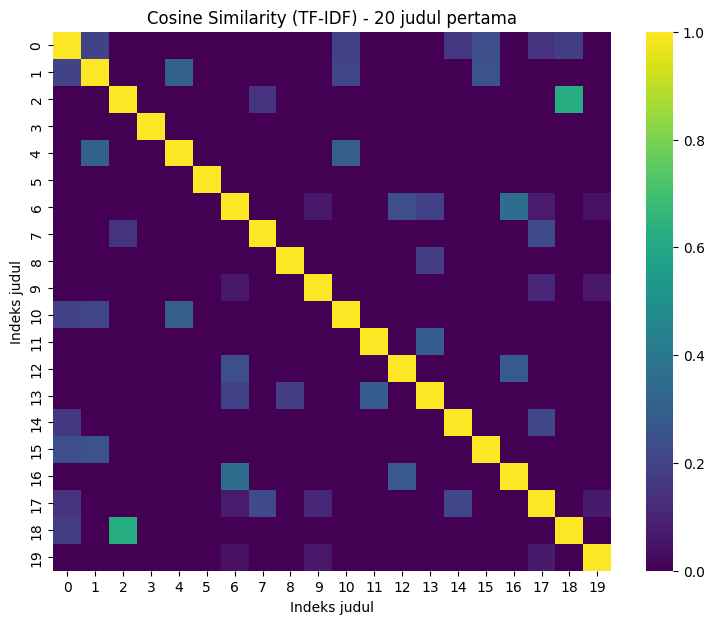

In [13]:
# Heatmap 20 judul pertama (Cosine TF-IDF)
n = 20
plt.figure(figsize=(9, 7))
sns.heatmap(sim_tfidf[:n, :n], cmap="viridis", vmin=0, vmax=1,
            xticklabels=range(n), yticklabels=range(n))
plt.title("Cosine Similarity (TF-IDF) - 20 judul pertama")
plt.xlabel("Indeks judul"); plt.ylabel("Indeks judul")
plt.show()

## Jaccard Similarity

Jaccard dihitung pada vektor **One Hot (binary)**: irisan kata dibagi gabungan kata dua judul. Seperti contoh modul, `similarity = 1 - distance` (distance dari `pdist(..., metric='jaccard')`).

In [14]:
# Cara modul: jarak Jaccard dengan pdist
dist_jac = squareform(pdist(X_onehot, metric="jaccard"))
sim_jac_scipy = 1 - dist_jac

# Perhitungan matriks (irisan / gabungan). Judul dengan vektor nol diberi similarity 0
inter = X_onehot @ X_onehot.T
size  = X_onehot.sum(axis=1)
union = size[:, None] + size[None, :] - inter
sim_jac = np.divide(inter, union, out=np.zeros(inter.shape, dtype=float), where=union > 0)
np.fill_diagonal(sim_jac, 1.0)

# Pastikan hasilnya sama dengan scipy untuk judul yang tidak kosong
ok = size > 0
print("Sama dengan scipy:", np.allclose(sim_jac[np.ix_(ok, ok)], sim_jac_scipy[np.ix_(ok, ok)]))

print("Top 10 pasangan judul paling mirip - Jaccard (One Hot)")
top_pairs(sim_jac)

Sama dengan scipy: True
Top 10 pasangan judul paling mirip - Jaccard (One Hot)


,doc_i,doc_j,similarity,judul_i,judul_j
0,23,74,1.0000,Ayo Daftar Tokoh Muda Inspiratif Penghargaan Energi Subroto di Sini,"Informasi Lengkap Penghargaan Energi Subroto, Ayo Daftar di Sini"
1,39,81,0.8000,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini","Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini"
2,38,80,0.7778,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi
3,20,63,0.7000,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini
4,20,38,0.7000,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi
5,19,62,0.7000,IHSG Masih Tertahan di Bawah 6.000 Meski 336 Saham Hijau Sore Ini,"IHSG Meradang di Bawah Level 6.000 Sore Ini, 602 Saham Merah"
6,20,80,0.6667,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi
7,9,25,0.6667,BGN Tutup Permanen 2 Dapur MBG di Jateng,"BGN Uji Coba MBG Prasmanan di 62 Dapur, Target 5.000 SPPG Akhir 2026"
8,33,65,0.6000,"Satgas P2BBL Diresmikan, Bergerak Lawan Penyelundupan Benih Lobster","Potensi Benih Lobster 465,8 Juta Ekor, Pemerintah Bentuk Satgas Khusus"
9,9,82,0.6000,BGN Tutup Permanen 2 Dapur MBG di Jateng,BGN Bongkar Modus Penipuan Janjikan Percepatan Aktivasi Dapur MBG


## Perbandingan Semua Metode

Skor lima metode pada **10 pasangan teratas Cosine TF-IDF**, lalu korelasi antar metode pada seluruh pasangan judul.

In [15]:
methods = {
    "Cosine BoW": sim_bow,
    "Cosine TF-IDF": sim_tfidf,
    "Cosine Word2Vec": sim_w2v,
    "Cosine FastText": sim_ft,
    "Jaccard One Hot": sim_jac,
}

top = top_pairs(sim_tfidf, 10)
comp = top[["doc_i", "doc_j"]].copy()
for name, S in methods.items():
    comp[name] = S[top["doc_i"], top["doc_j"]].round(4)
comp["judul_i"] = top["judul_i"]
comp["judul_j"] = top["judul_j"]
comp

,doc_i,doc_j,Cosine BoW,Cosine TF-IDF,Cosine Word2Vec,Cosine FastText,Jaccard One Hot,judul_i,judul_j
0,23,74,1.0000,1.0000,1.0000,0.9954,1.0000,Ayo Daftar Tokoh Muda Inspiratif Penghargaan Energi Subroto di Sini,"Informasi Lengkap Penghargaan Energi Subroto, Ayo Daftar di Sini"
1,39,81,0.8889,0.8807,0.9206,0.9885,0.8000,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini","Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini"
2,38,80,0.8819,0.8531,0.9357,0.9937,0.7778,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi
3,33,65,0.7746,0.8220,0.6818,0.8742,0.6000,"Satgas P2BBL Diresmikan, Bergerak Lawan Penyelundupan Benih Lobster","Potensi Benih Lobster 465,8 Juta Ekor, Pemerintah Bentuk Satgas Khusus"
4,9,25,0.8165,0.8070,0.7636,0.9136,0.6667,BGN Tutup Permanen 2 Dapur MBG di Jateng,"BGN Uji Coba MBG Prasmanan di 62 Dapur, Target 5.000 SPPG Akhir 2026"
5,20,63,0.8250,0.8021,0.8902,0.9926,0.7000,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini
6,9,82,0.7500,0.8018,0.6612,0.9408,0.6000,BGN Tutup Permanen 2 Dapur MBG di Jateng,BGN Bongkar Modus Penipuan Janjikan Percepatan Aktivasi Dapur MBG
7,20,38,0.8250,0.8011,0.9055,0.9919,0.7000,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi
8,16,56,0.7303,0.7817,0.7589,0.9563,0.5714,Pertamina Patra Niaga Kebut Pemulihan Pasokan BBM Bali 24 Jam,Pertamina Patra Niaga Antisipasi Lonjakan Konsumsi BBM di Bondowoso
9,19,62,0.8250,0.7761,0.9151,0.9885,0.7000,IHSG Masih Tertahan di Bawah 6.000 Meski 336 Saham Hijau Sore Ini,"IHSG Meradang di Bawah Level 6.000 Sore Ini, 602 Saham Merah"


Korelasi skor antar metode (semua pasangan judul)


,Cosine BoW,Cosine TF-IDF,Cosine Word2Vec,Cosine FastText,Jaccard One Hot
Cosine BoW,1.000,0.946,0.692,0.219,0.971
Cosine TF-IDF,0.946,1.000,0.628,0.169,0.959
Cosine Word2Vec,0.692,0.628,1.000,0.330,0.663
Cosine FastText,0.219,0.169,0.330,1.000,0.210
Jaccard One Hot,0.971,0.959,0.663,0.210,1.000


Ringkasan distribusi skor


,rata-rata,median,maks,% pasangan skor = 0
Cosine BoW,0.0441,0.0000,1.0000,81.9406
Cosine TF-IDF,0.0326,0.0000,1.0000,81.9406
Cosine Word2Vec,0.1848,0.1684,1.0000,0.0000
Cosine FastText,0.9123,0.9242,0.9954,0.0000
Jaccard One Hot,0.0249,0.0000,1.0000,81.9406


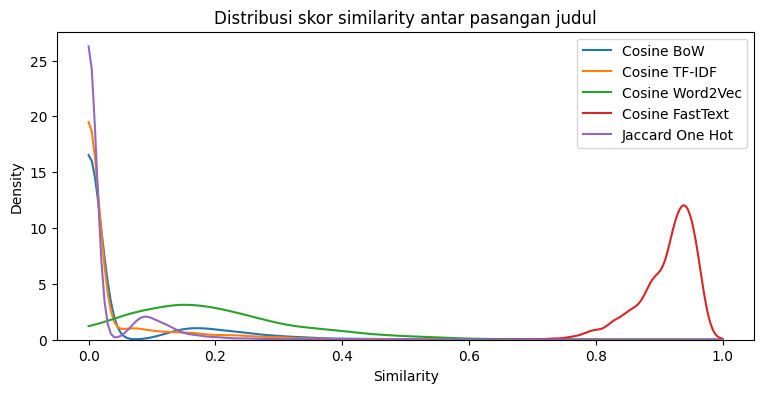

In [16]:
iu = np.triu_indices(len(df_pre), k=1)
flat = pd.DataFrame({name: S[iu] for name, S in methods.items()})

print("Korelasi skor antar metode (semua pasangan judul)")
display(flat.corr().round(3))

summary = pd.DataFrame({
    "rata-rata": flat.mean(),
    "median": flat.median(),
    "maks": flat.max(),
    "% pasangan skor = 0": (flat == 0).mean() * 100,
}).round(4)
print("Ringkasan distribusi skor")
display(summary)

plt.figure(figsize=(9, 4))
for name in methods:
    sns.kdeplot(flat[name], label=name, clip=(0, 1))
plt.title("Distribusi skor similarity antar pasangan judul")
plt.xlabel("Similarity"); plt.legend(); plt.show()

## Pencarian Judul Mirip dengan Query

Seperti contoh *arxiv* pada modul: query diubah ke representasi yang sama dengan korpus, lalu diambil `TopK` judul dengan similarity tertinggi.

In [17]:
def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def search(query, TopK=5):
    q = preprocess_text(query)
    vocab = tfidf_vectorizer.vocabulary_
    print(f"Query: '{q}' | kata yang ada di vocabulary:", [w for w in q.split() if w in vocab])

    # Cosine TF-IDF
    s_tfidf = cosine_similarity(X_tfidf, tfidf_vectorizer.transform([q]))[:, 0]
    # Jaccard One Hot
    q_bin = onehot_vectorizer.transform([q]).toarray()
    s_jac = 1 - cdist(X_onehot, q_bin, metric="jaccard")[:, 0]
    s_jac = np.nan_to_num(s_jac, nan=0.0)
    # Cosine Word2Vec
    q_w2v = get_document_vector(q.split(), model_w2v).reshape(1, -1)
    s_w2v = cosine_similarity(X_w2v, q_w2v)[:, 0]

    out = {}
    for name, s in [("Cosine TF-IDF", s_tfidf), ("Jaccard", s_jac), ("Cosine Word2Vec", s_w2v)]:
        idx = np.argsort(s)[::-1][:TopK]
        out[name] = pd.DataFrame({"Judul": df["raw_title"].values[idx], "Similarity": s[idx].round(4)})
    return out

for q in ["ihsg menguat rupiah", "harga emas naik", "subsidi pemerintah stimulus ekonomi"]:
    res = search(q)
    for name, tbl in res.items():
        print(f"\n-- {name}")
        display(tbl)
    print("=" * 100)

Query: 'ihsg menguat rupiah' | kata yang ada di vocabulary: ['ihsg', 'rupiah']

-- Cosine TF-IDF


,Judul,Similarity
0,IHSG Diperkirakan Ceria Awali Pekan Ini,0.4141
1,IHSG Diproyeksi Makin Turun Hari Ini,0.3573
2,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.2713
3,"IHSG Meradang di Bawah Level 6.000 Sore Ini, 602 Saham Merah",0.2575
4,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,0.2547



-- Jaccard


,Judul,Similarity
0,IHSG Diperkirakan Ceria Awali Pekan Ini,0.2500
1,IHSG Diproyeksi Makin Turun Hari Ini,0.2000
2,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.1250
3,"IHSG Meradang di Bawah Level 6.000 Sore Ini, 602 Saham Merah",0.1111
4,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,0.1111



-- Cosine Word2Vec


...

,Judul,Similarity
0,AirAsia Dikabarkan Cari Dukungan Pemerintah Malaysia di Tengah Krisis,0.4065
1,Robert E Hall dan Michael Woodford Jadi Peraih Nobel Ekonomi 2026,0.3934
2,"Ekonomi Vietnam Terus Meroket, Mengapa Indonesia Bisa Tertinggal?",0.3861
3,"Buruh Desak Pemerintah Batasi Outsourcing, Hapus Pesangon 0,5 Kali",0.3533
4,Pemerintah Matangkan Tugas BRAN Biar Tak Tumpang Tindih dengan ATR/BPN,0.3533



-- Jaccard


,Judul,Similarity
0,Pemerintah Matangkan Tugas BRAN Biar Tak Tumpang Tindih dengan ATR/BPN,0.25
1,AirAsia Dikabarkan Cari Dukungan Pemerintah Malaysia di Tengah Krisis,0.25
2,"Buruh Desak Pemerintah Batasi Outsourcing, Hapus Pesangon 0,5 Kali",0.25
3,"Ekonomi Vietnam Terus Meroket, Mengapa Indonesia Bisa Tertinggal?",0.25
4,Robert E Hall dan Michael Woodford Jadi Peraih Nobel Ekonomi 2026,0.20



-- Cosine Word2Vec


,Judul,Similarity
0,Pemerintah Evaluasi Penanganan Karhutla di Kalimantan Sore Ini,0.6305
1,RI-Mesir Sepakat Perkuat Kerja Sama Ekonomi hingga Pertahanan,0.5796
2,AirAsia Dikabarkan Cari Dukungan Pemerintah Malaysia di Tengah Krisis,0.5728
3,Pemerintah Matangkan Tugas BRAN Biar Tak Tumpang Tindih dengan ATR/BPN,0.5455
4,Kemenhub Pantau Dampak Serangan di Riyadh Saudi ke Penerbangan RI,0.5032


## Analisis Text Similarity

**Cosine vs Jaccard.** Cosine similarity memperhitungkan bobot kata (frekuensi pada BoW atau bobot TF-IDF) dan panjang vektor dinormalisasi, sedangkan Jaccard hanya melihat ada tidaknya kata (irisan dibagi gabungan). Karena judul berita sangat pendek (sekitar 5-12 kata) dan hampir tidak ada kata yang berulang dalam satu judul, skor Cosine BoW, Cosine TF-IDF, dan Jaccard cenderung sangat berkorelasi (lihat tabel korelasi); perbedaan utamanya adalah skala nilainya (Jaccard umumnya lebih rendah daripada Cosine untuk pasangan yang sama).

**BoW vs TF-IDF.** Pada BoW semua kata bernilai sama, sehingga dua judul bisa tampak mirip hanya karena sama-sama memakai kata umum seperti "di", "ke", "ini", "yang". TF-IDF menurunkan bobot kata umum tersebut dan menaikkan bobot kata khas (misalnya nama lembaga, komoditas, atau istilah pasar), sehingga pasangan dengan skor tinggi lebih sering benar-benar membahas topik yang sama. Lihat tabel perbandingan: pasangan yang skornya tinggi di BoW tetapi turun di TF-IDF umumnya mirip karena kata umum.

**Word2Vec/FastText.** Rata-rata embedding menangkap kemiripan konteks, bukan kata yang sama, sehingga hampir semua pasangan judul mendapat skor positif (persentase pasangan bernilai 0 hampir nol, berbeda dengan BoW/TF-IDF/Jaccard). Karena korpus hanya ratusan judul, embedding belum kuat, sehingga skor cenderung seragam dan kurang membedakan topik; kata sangat umum juga ikut mendominasi rata-rata vektor.

**Keterbatasan.**

(1) Pada `min_df=2`, judul yang semua katanya muncul hanya sekali memiliki vektor nol sehingga similarity-nya 0 dengan semua judul.

(2) Metode berbasis kata tidak mengenali sinonim (misal "melemah" vs "anjlok") dan tidak mengerti urutan kata.

(3) Query yang kata-katanya tidak ada di vocabulary tidak menghasilkan skor yang bermakna; lihat baris "kata yang ada di vocabulary" pada hasil pencarian.

**Kesimpulan.** Untuk judul berita pendek, **Cosine + TF-IDF** paling informatif untuk mencari judul yang topiknya sama, Jaccard cocok sebagai pembanding sederhana berbasis kesamaan kata, dan embedding Word2Vec/FastText baru bermanfaat bila korpus diperbesar (lebih banyak halaman indeks).